# Summative Lab - Analytics Firm Clients: Customer Reviews Analysis

Three parts on one dataset of Amazon customer reviews (`amazon_reviews_lab.csv`):
1. **NLP** - clean review text, find frequent words and bigrams
2. **Time Series** - review volume and ratings over time (stationarity, ARIMA forecast)
3. **Neural Networks** - predict the star rating from review text

# Part 1 : NLP

In [3]:
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string
from collections import Counter


# For text preprocessing
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.util import bigrams


# Download necessary NLTK data
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger')
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger_eng')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptr

True

In [4]:
# load and explore dataset
df = pd.read_csv('amazon_reviews_lab.csv')
print(df.shape)
df.head()

(997, 9)


,product_id,rating,review_text,review_summary,review_time_raw,unix_review_time,timestamp,sentiment_label,review_length_words
0,6301977173,2,This film is definitely not for anyone who is ...,The best of Mark Twain's work - left out!,"05 12, 2000",9.580896e+08,2000-05-12,negative,302
1,6301977173,5,This movie was playing at Radio City Music Hal...,The best Tom Sawyer i ever saw.,"08 26, 2002",1.030320e+09,2002-08-26,positive,168
2,6301977173,1,I would love to buy this movie as I have been ...,Why no Widescreen?,"08 6, 2005",1.123286e+09,2005-08-06,negative,60
3,6301977173,1,The advertisment for this DVD on Amazon was in...,False advertising on this DVD,"09 11, 2005",1.126397e+09,2005-09-11,negative,104
4,9575871979,5,I bought some of these to try with a light usi...,Work GREAT!!,"10 15, 2007",1.192406e+09,2007-10-15,positive,60


In [5]:
# columns
df.columns

Index(['product_id', 'rating', 'review_text', 'review_summary',
       'review_time_raw', 'unix_review_time', 'timestamp', 'sentiment_label',
       'review_length_words'],
      dtype='object')

In [6]:
df['rating'].value_counts().sort_index()

rating
1     87
2     48
3     94
4    188
5    580
Name: count, dtype: int64

In [7]:
# data types
df.dtypes

product_id              object
rating                   int64
review_text             object
review_summary          object
review_time_raw         object
unix_review_time       float64
timestamp               object
sentiment_label         object
review_length_words      int64
dtype: object

In [8]:
display(df[['rating', 'review_text', 'sentiment_label']].head(5))

,rating,review_text,sentiment_label
0,2,This film is definitely not for anyone who is ...,negative
1,5,This movie was playing at Radio City Music Hal...,positive
2,1,I would love to buy this movie as I have been ...,negative
3,1,The advertisment for this DVD on Amazon was in...,negative
4,5,I bought some of these to try with a light usi...,positive


In [9]:
# missing values
df.isnull().sum()

product_id             0
rating                 0
review_text            0
review_summary         0
review_time_raw        0
unix_review_time       0
timestamp              0
sentiment_label        0
review_length_words    0
dtype: int64

In [10]:
# duplicates
df.duplicated().sum()

np.int64(0)

In [11]:
# summary statistics
df.describe()

,rating,unix_review_time,review_length_words
count,997.000000,9.970000e+02,997.000000
mean,4.129388,1.344766e+09,146.374122
std,1.280181,4.411420e+07,216.126770
min,1.000000,9.580896e+08,5.000000
25%,4.000000,1.311898e+09,32.000000
50%,5.000000,1.356048e+09,67.000000
75%,5.000000,1.379462e+09,165.000000
max,5.000000,1.405555e+09,2079.000000


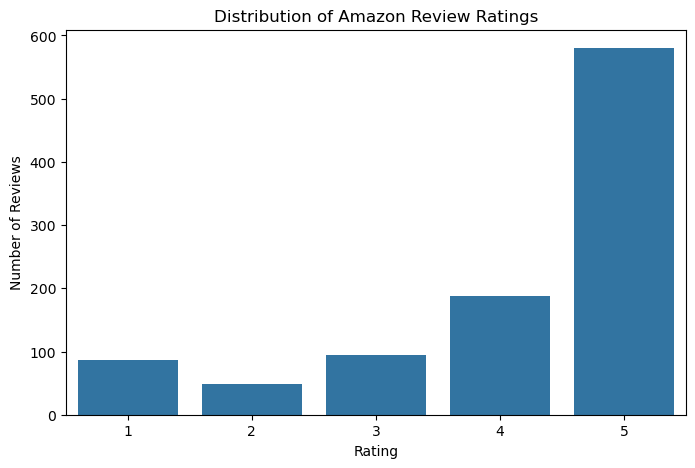

In [12]:
# Distribution of customer ratings
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='rating')

plt.title('Distribution of Amazon Review Ratings')
plt.xlabel('Rating')
plt.ylabel('Number of Reviews')
plt.show()


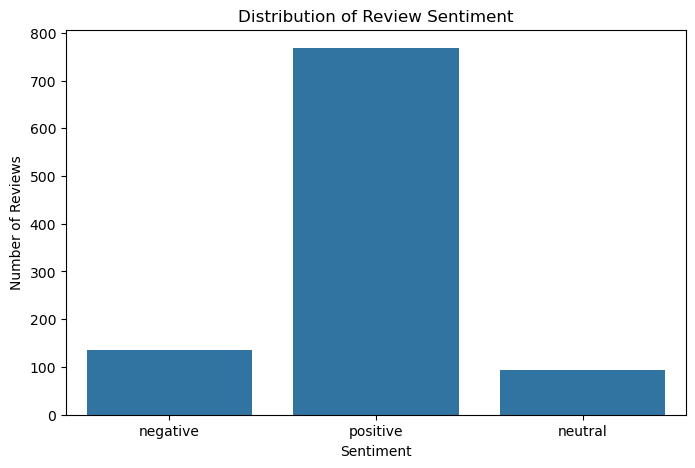

In [13]:
# sentiment distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='sentiment_label')

plt.title('Distribution of Review Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')
plt.show()

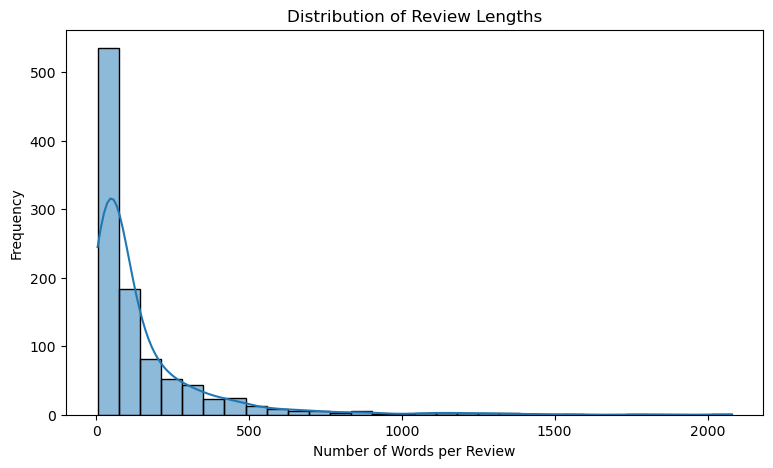

In [14]:
# review length distribution
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x='review_length_words', bins=30, kde=True)

plt.title('Distribution of Review Lengths')
plt.xlabel('Number of Words per Review')
plt.ylabel('Frequency')
plt.show()

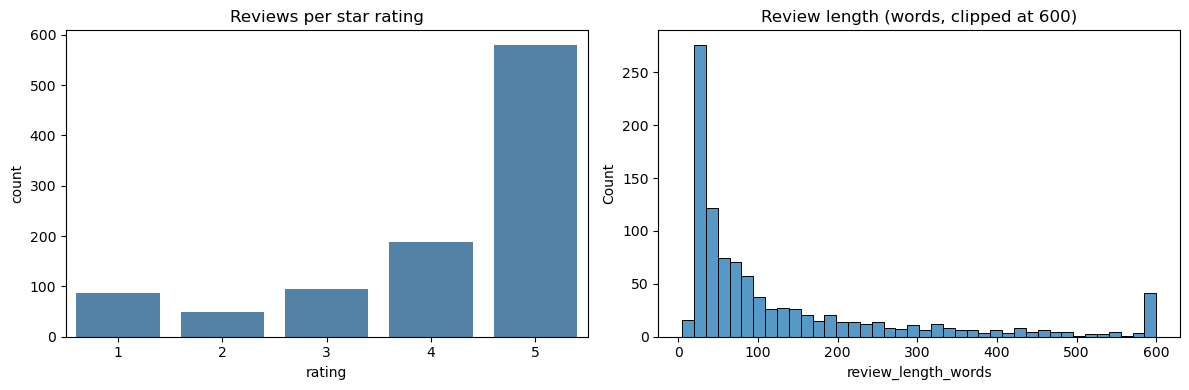

count     997.000000
mean      146.374122
std       216.126770
min         5.000000
25%        32.000000
50%        67.000000
75%       165.000000
max      2079.000000
Name: review_length_words, dtype: float64
Empty reviews: 0


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x='rating', data=df, ax=ax[0], color='steelblue'); ax[0].set_title('Reviews per star rating')
sns.histplot(df['review_length_words'].clip(upper=600), bins=40, ax=ax[1]); ax[1].set_title('Review length (words, clipped at 600)')
plt.tight_layout(); plt.show()
print(df['review_length_words'].describe())
print("Empty reviews:", (df['review_text'].str.strip() == '').sum())

In [16]:
# Preprocessing
stop_words = set(stopwords.words('english')) - {'not', 'no', 'nor'}
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = str(text).lower()                                          # 1. lowercase
    text = re.sub(r'http\S+|www\.\S+', ' ', text)                     # 2. remove URLs
    text = text.translate(str.maketrans(string.punctuation, ' ' * len(string.punctuation)))  # 3. remove punctuation
    tokens = word_tokenize(text)                                      # 4. tokenize
    tokens = [t for t in tokens if t.isalpha() and len(t) > 1]        # 5. alphabetic only (2+ letters so 'no' survives)
    tokens = [t for t in tokens if t not in stop_words]               # 6. stopwords
    tokens = [lemmatizer.lemmatize(t) for t in tokens]                # 7. lemmatize
    return tokens                                                     # 8. cleaned tokens

df['processed_tokens'] = df['review_text'].apply(preprocess_text)
df['processed_text'] = df['processed_tokens'].apply(' '.join)

i = 5
print("RAW  :", df['review_text'].iloc[i][:300])
print("CLEAN:", df['processed_text'].iloc[i][:300])

RAW  : For the money you can't go wrong. Yes, it has a litlle play in the mechanism but, you can adjust your mounting to accomodate that. It works great and frees up counter space. I would do it all again. Why spend 3 times more.
CLEAN: money go wrong yes litlle play mechanism adjust mounting accomodate work great free counter space would spend time


In [17]:
# validate preprocessing
raw_vocab = set(w for t in df['review_text'] for w in re.findall(r'[a-z]+', t.lower()))
clean_vocab = set(w for toks in df['processed_tokens'] for w in toks)
print(f"Vocabulary: {len(raw_vocab):,} raw -> {len(clean_vocab):,} cleaned "
      f"({100 * (1 - len(clean_vocab) / len(raw_vocab)):.1f}% smaller)")
print("Avg tokens per review: raw", round(df['review_length_words'].mean(), 1),
      "-> cleaned", round(df['processed_tokens'].str.len().mean(), 1))
print("Stopwords left in vocabulary:", len([w for w in clean_vocab if w in stop_words]))
print("Reviews that became empty after cleaning:", (df['processed_tokens'].str.len() == 0).sum())

Vocabulary: 7,532 raw -> 6,563 cleaned (12.9% smaller)
Avg tokens per review: raw 146.4 -> cleaned 73.0
Stopwords left in vocabulary: 9
Reviews that became empty after cleaning: 0


In [18]:
# word and bigram frequencies
all_tokens = [t for toks in df['processed_tokens'] for t in toks]
word_counts = Counter(all_tokens)
top_words = word_counts.most_common(20)
print("Top 20 words:", top_words)

all_bigrams = [b for toks in df['processed_tokens'] for b in bigrams(toks)]
bigram_counts = Counter(all_bigrams)
top_bigrams = bigram_counts.most_common(20)
print("\nTop 20 bigrams:")
for b, c in top_bigrams: print(f"  {' '.join(b):25s} {c}")

Top 20 words: [('nook', 1577), ('not', 1064), ('book', 986), ('one', 596), ('kindle', 590), ('screen', 535), ('like', 474), ('read', 464), ('work', 463), ('great', 444), ('tablet', 443), ('use', 432), ('tv', 427), ('get', 426), ('no', 408), ('device', 399), ('would', 383), ('good', 348), ('reader', 346), ('well', 336)]

Top 20 bigrams:
  barnes noble              166
  nook color                135
  battery life              98
  touch screen              96
  sd card                   89
  nook hd                   80
  work great                65
  nook tablet               64
  kindle fire               61
  work well                 59
  read book                 58
  no problem                53
  wall mount                53
  wi fi                     47
  simple touch              45
  customer service          41
  android tablet            40
  micro sd                  39
  original nook             38
  nook simple               37


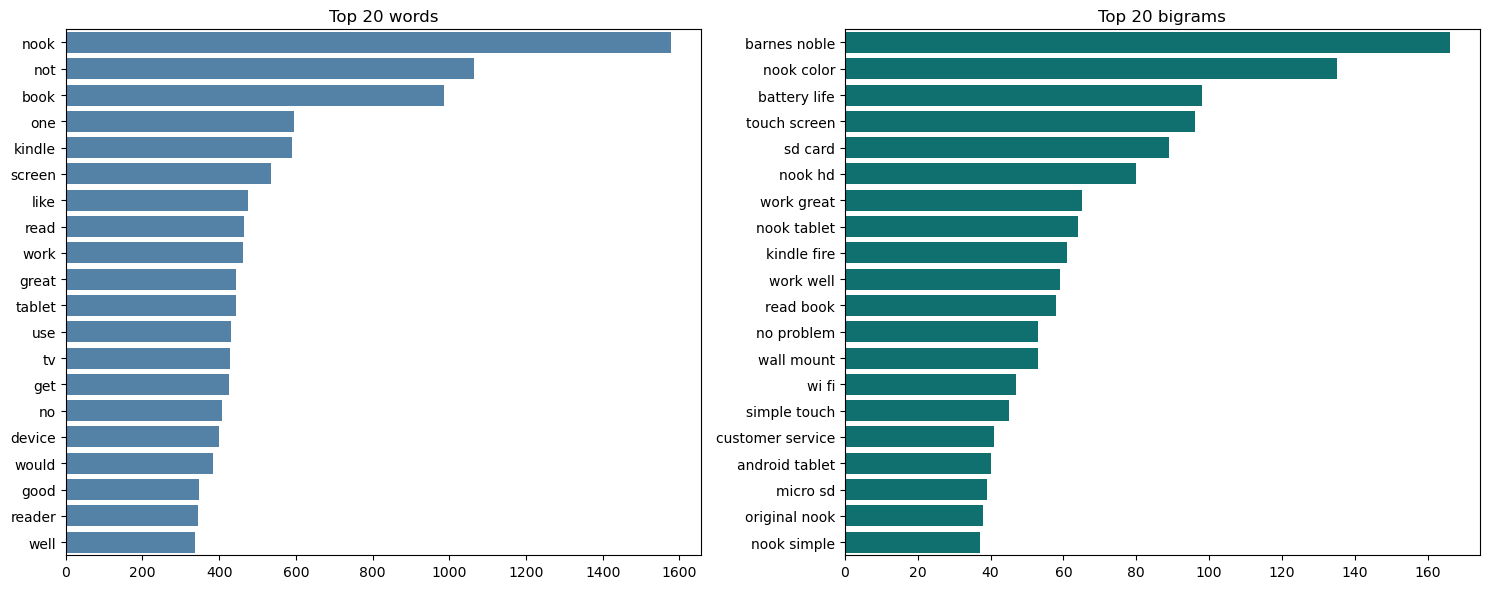

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
w, c = zip(*top_words)
sns.barplot(x=list(c), y=list(w), ax=ax[0], color='steelblue'); ax[0].set_title('Top 20 words')
b, c = zip(*top_bigrams)
sns.barplot(x=list(c), y=[' '.join(x) for x in b], ax=ax[1], color='teal'); ax[1].set_title('Top 20 bigrams')
plt.tight_layout(); plt.show()

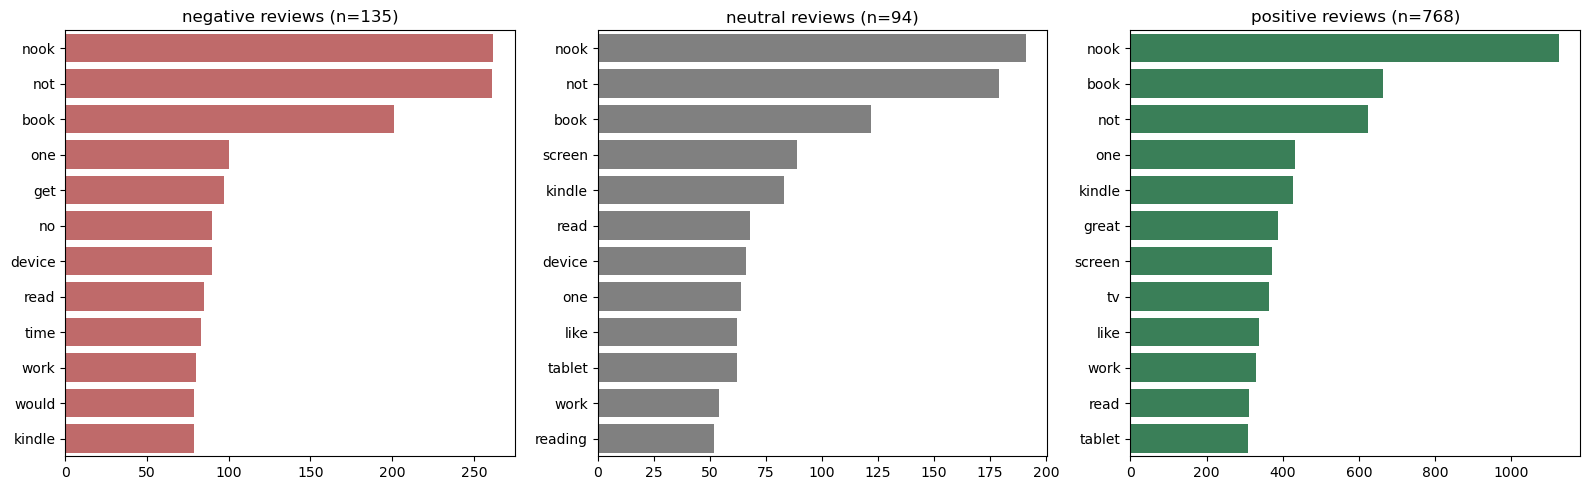

In [20]:
# language by sentiment
def top_by_group(mask, k=12):
    toks = [t for toks in df.loc[mask, 'processed_tokens'] for t in toks]
    return Counter(toks).most_common(k)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, lab in zip(axes, ['negative', 'neutral', 'positive']):
    w, c = zip(*top_by_group(df['sentiment_label'] == lab))
    sns.barplot(x=list(c), y=list(w), ax=ax, color={'negative': 'indianred', 'neutral': 'gray', 'positive': 'seagreen'}[lab])
    ax.set_title(f'{lab} reviews (n={int((df.sentiment_label == lab).sum())})')
plt.tight_layout(); plt.show()

In [21]:
# Distinctive words: TF-IDF mean by sentiment group
from sklearn.feature_extraction.text import TfidfVectorizer
tv = TfidfVectorizer(min_df=5, max_df=0.5)
M = tv.fit_transform(df['processed_text'])
terms = np.array(tv.get_feature_names_out())
for lab in ['negative', 'neutral', 'positive']:
    mean = np.asarray(M[(df['sentiment_label'] == lab).values].mean(axis=0)).ravel()
    print(f"{lab:9s}", ', '.join(terms[mean.argsort()[::-1][:12]]))

negative  not, nook, book, device, get, read, one, card, buy, kindle, tablet, screen
neutral   nook, not, book, tablet, work, screen, kindle, device, tv, one, mount, bought
positive  nook, tv, great, work, mount, cable, not, book, one, price, good, kindle


In [22]:
!pip install wordcloud

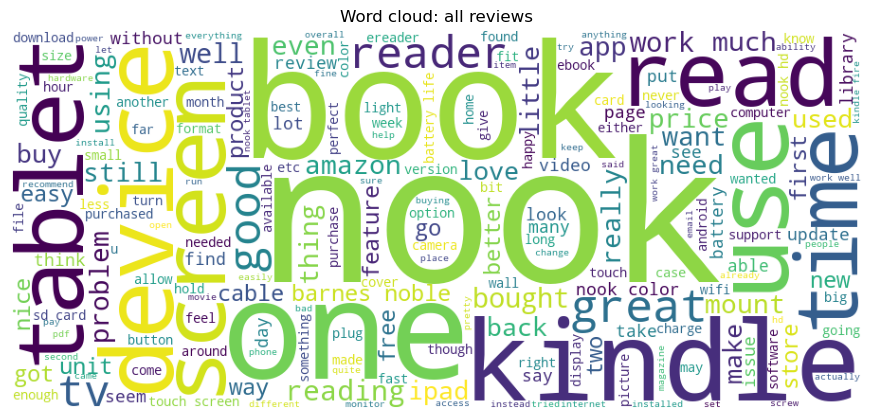

In [23]:
from wordcloud import WordCloud
wc = WordCloud(width=900, height=400, background_color='white').generate(' '.join(all_tokens))
plt.figure(figsize=(11, 5)); plt.imshow(wc); plt.axis('off'); plt.title('Word cloud: all reviews'); plt.show()

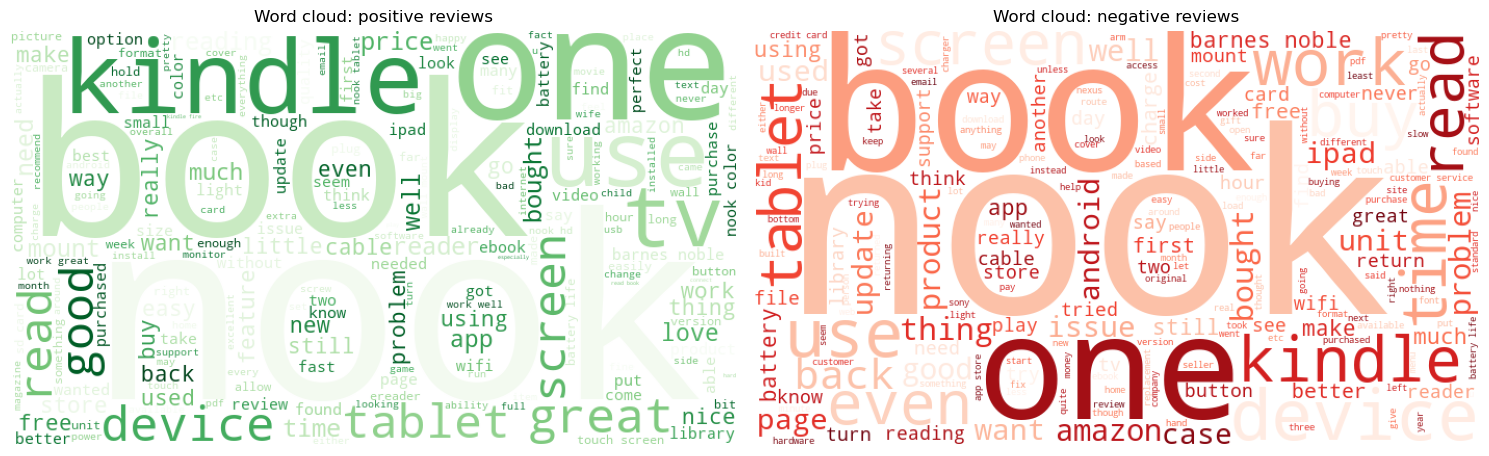

In [24]:
from wordcloud import WordCloud

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, lab, cmap in zip(axes, ['positive', 'negative'], ['Greens', 'Reds']):
    txt = ' '.join(df.loc[df['sentiment_label'] == lab, 'processed_text'])
    wc = WordCloud(width=700, height=400, background_color='white', colormap=cmap).generate(txt)
    ax.imshow(wc)
    ax.axis('off')
    ax.set_title(f'Word cloud: {lab} reviews')
plt.tight_layout()
plt.show()

**Reflection (Part 1):**
Keeping the negations (*not*, *no*) makes them among the most frequent tokens, and bigrams like "no problem" show that they carry sentiment. The vocabulary is dominated by e-reader and tablet terms (nook, kindle, screen, tablet, reader, device, battery life, touch screen, "Barnes & Noble", "Nook Color", "Kindle Fire"), plus accessory terms (wall mount, cable, micro card). So the reviews are about consumer electronics, mainly e-readers and their accessories, and customers talk about the screen, battery, setup and reading experience. Sentiment words are mostly favorable: "great", "good", "love", "work great", "work well" and "work fine" are among the most frequent, consistent with the 58% share of 5-star reviews. Splitting by sentiment shows the positive group uses "great", "love", "price", "mount" and "cable" (accessories that simply work), while the negative group leans on "device", "card", "buy" and "customer" (hardware failures, memory cards, customer service), and many core product words (nook, book, kindle) appear in every group, so they do not separate sentiment.